# 🏦 Bank Account Fraud (BAF) - MDPI Replication
* Shehbaz Makhmoor Ali

This notebook replicates the baseline methodology from the December 2025 MDPI paper *"Objective over Architecture."* It applies a static cost-sensitive penalty to both a LightGBM and a Gated Recurrent Unit (GRU) to handle extreme 99-to-1 tabular class imbalance.

Mounted at /content/drive
Loading dataset...
Dataset Shape: 1,000,000 rows and 32 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h  

None

/tmp/ipykernel_810/883020519.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='fraud_bool', palette=['#1f77b4', '#d62728'])


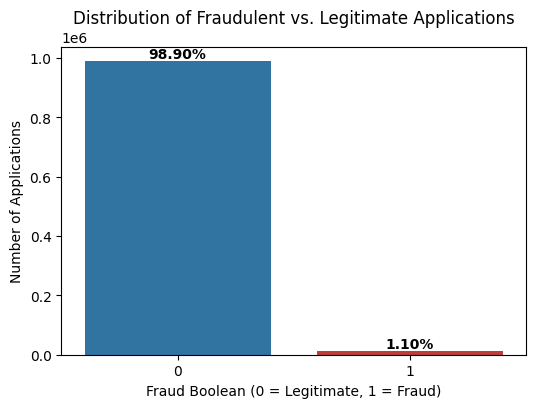

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# 1. Load the dataset from Google Drive
print("Loading dataset...")
df = pd.read_csv('/content/drive/MyDrive/AI_LAB/Base.csv')

# 2. Check the exact row and column count
print(f"Dataset Shape: {df.shape[0]:,} rows and {df.shape[1]} columns")

# 3. Quick look at the data types
display(df.info())

# 4. Visualize the extreme class imbalance
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='fraud_bool', palette=['#1f77b4', '#d62728'])
plt.title('Distribution of Fraudulent vs. Legitimate Applications')
plt.xlabel('Fraud Boolean (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Applications')

# Add percentage labels on top of the bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontweight='bold')

plt.show()

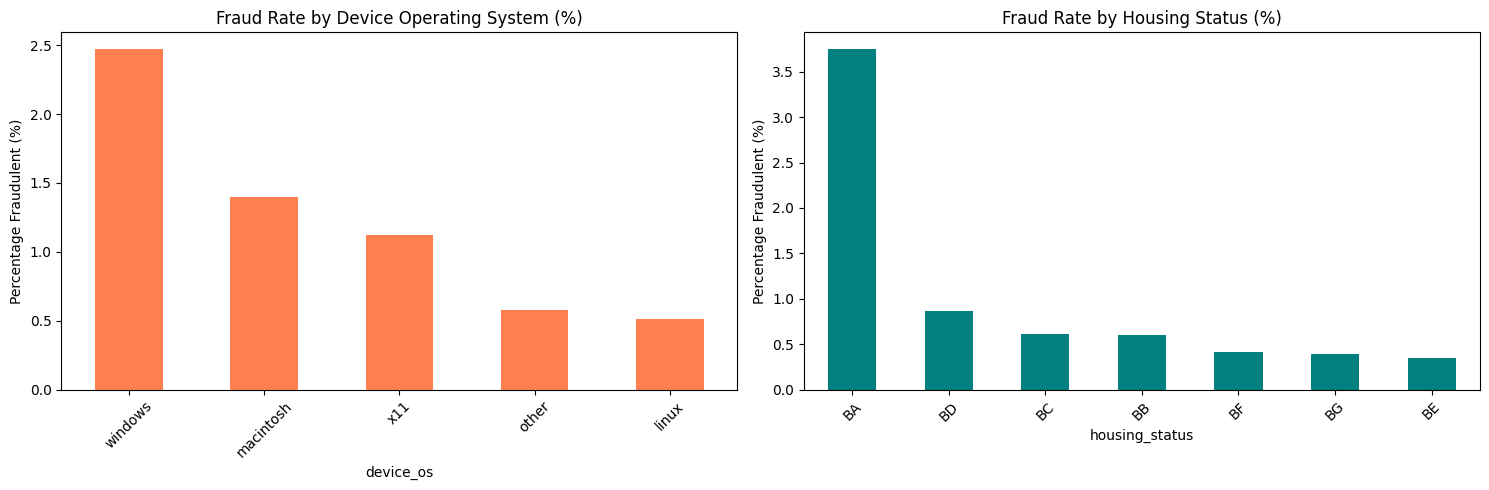

In [2]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Fraud Rate by Device OS
# We calculate the mean of 'fraud_bool' which gives us the exact percentage of fraud per OS
os_fraud_rate = df.groupby('device_os')['fraud_bool'].mean() * 100
os_fraud_rate.sort_values(ascending=False).plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Fraud Rate by Device Operating System (%)')
axes[0].set_ylabel('Percentage Fraudulent (%)')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Fraud Rate by Housing Status
housing_fraud_rate = df.groupby('housing_status')['fraud_bool'].mean() * 100
housing_fraud_rate.sort_values(ascending=False).plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Fraud Rate by Housing Status (%)')
axes[1].set_ylabel('Percentage Fraudulent (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, precision_recall_curve, auc
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
X = df.drop(columns=['fraud_bool'])
y = df['fraud_bool']

# 3. Identify Column Types
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# 4. Build the Pipeline (Matching the Paper exactly)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(missing_values=-1, strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='__missing__')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 5. Split and Process Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 6. Calculate Static Penalty
fraud_ratio = y_train.value_counts()[0] / y_train.value_counts()[1]
print(f"Calculated Static Class Weight (Penalty): {fraud_ratio:.2f}")

Calculated Static Class Weight (Penalty): 89.67


## 🌳 Baseline 1: LightGBM (Classical Tree-Based)
Training the standard gradient boosting model with the static class weight applied to the objective.

In [6]:
# Initialize and Train LightGBM
lgbm = LGBMClassifier(
    scale_pos_weight=fraud_ratio, # The critical 89.67 penalty
    random_state=42,
    n_jobs=-1
)

print("Training LightGBM...")
lgbm.fit(X_train_processed, y_train)

# Evaluate PR-AUC
y_probs_lgbm = lgbm.predict_proba(X_test_processed)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_probs_lgbm)
pr_auc_lgbm = auc(recall, precision)

y_pred_lgbm = lgbm.predict(X_test_processed)

print(f"\n--- LIGHTGBM REPLICATION RESULTS ---")
print(f"PR-AUC Score: {pr_auc_lgbm:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred_lgbm))

Training LightGBM...
[LightGBM] [Info] Number of positive: 8823, number of negative: 791177
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.557162 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3246
[LightGBM] [Info] Number of data points in the train set: 800000, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.011029 -> initscore=-4.496160
[LightGBM] [Info] Start training from score -4.496160

--- LIGHTGBM REPLICATION RESULTS ---
PR-AUC Score: 0.1549
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91    197794
           1       0.05      0.79      0.09      2206

    accuracy                           0.83    200000
   macro avg       0.52      0.81      0.50    200000
weighted avg       0.99      0.83      0.90    200000



## 🧠 Baseline 2: Gated Recurrent Unit (Deep Learning)
Reshaping the 2D tabular array into a 3D sequential format and training the GRU to establish the high-recall performance ceiling.

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout

# 1. Reshape data for GRU (Samples, Timesteps, Features)
# We treat the entire row of features as a single timestep containing all column data
X_train_gru = np.expand_dims(X_train_processed, axis=1)
X_test_gru = np.expand_dims(X_test_processed, axis=1)

# 2. Build GRU Architecture
model = Sequential([
    GRU(64, input_shape=(X_train_gru.shape[1], X_train_gru.shape[2]), return_sequences=True),
    Dropout(0.2),
    GRU(32),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy')

# 3. Train with the Static Weight Class dictionary
class_weight_dict = {0: 1.0, 1: fraud_ratio}

print("Training GRU Model (This may take a few minutes)...")
history = model.fit(
    X_train_gru, y_train,
    epochs=5,
    batch_size=2048,
    class_weight=class_weight_dict,
    validation_split=0.1,
    verbose=1
)

# 4. Evaluate PR-AUC
y_probs_gru = model.predict(X_test_gru).ravel()
precision_g, recall_g, _ = precision_recall_curve(y_test, y_probs_gru)
pr_auc_gru = auc(recall_g, precision_g)

# Convert probabilities to binary predictions (Threshold 0.5)
y_pred_gru = (y_probs_gru > 0.5).astype(int)

print(f"\n--- GRU REPLICATION RESULTS ---")
print(f"PR-AUC Score: {pr_auc_gru:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred_gru))

Training GRU Model (This may take a few minutes)...
Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - loss: 0.9537 - val_loss: 0.4433
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - loss: 0.8799 - val_loss: 0.4315
Epoch 3/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - loss: 0.8672 - val_loss: 0.4211
Epoch 4/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - loss: 0.8576 - val_loss: 0.3828
Epoch 5/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - loss: 0.8467 - val_loss: 0.4216
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step

--- GRU REPLICATION RESULTS ---
PR-AUC Score: 0.1555
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.81      0.89    197794
           1       0.04      0.80      0.08      2206

    accuracy                           0.81    200000
   macro avg       0.52      0.81      0.49    200000
weighted avg       0.99      0.81      0.88    200000

